In [6]:
# 儲存格 1：設定視覺化中文字型（繁體中文顯示）
# Cell 1: Set up visualization font (Traditional Chinese display)
# 匯入 glob 模組：用於批次搜尋字型檔路徑
# Import glob module: for batch searching font file paths

import glob
# 匯入 os 模組：處理檔案路徑拼接
# Import os module: for handling file path concatenation

import os
# 匯入 mplfonts 套件：提供中文字型檔與快速設定工具
# Import mplfonts package: provides Chinese fonts and quick setup tools

import mplfonts
# 從 Matplotlib 匯入字型管理器：用於手動註冊字型
# Import font manager from Matplotlib: used for manual font registration

from matplotlib import font_manager
# 匯入 Matplotlib 繪圖模組：建立圖表的基礎工具
# Import Matplotlib plotting module: basic tool for creating charts

import matplotlib.pyplot as plt
# 匯入 Seaborn 套件：進階統計繪圖（基於 Matplotlib）
# Import Seaborn package: advanced statistical plotting (based on Matplotlib)

import seaborn as sns
# 從 mplfonts 匯入快速套用字型函式
# Import quick font application function from mplfonts

from mplfonts import use_font

# 迴圈註冊 mplfonts 內附的所有 .otf / .ttf 字型檔
# Loop to register all .otf / .ttf font files included in mplfonts

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    # 將找到的字型逐一加入 Matplotlib 字型管理器
# Add found fonts one by one to Matplotlib font manager

    font_manager.fontManager.addfont(f)
# 套用 Noto Sans CJK SC 字型（支援繁體中文顯示）
# Apply Noto Sans CJK SC font (supports Traditional Chinese display)

use_font("Noto Sans CJK SC")
# 設定負號正常顯示，避免中文模式下變成方塊
# Set negative signs to display normally to avoid squares in Chinese mode

plt.rcParams['axes.unicode_minus'] = False
# 印出成功訊息，確認字型已載入
# Print success message to confirm font is loaded

print("繁體中文字型已成功載入！")

繁體中文字型已成功載入！


In [8]:
# 儲存格 2：匯入套件並讀取房產資料集
# Cell 2: Import packages and read the real estate dataset
# 匯入 Pandas：處理表格資料（DataFrame）的核心套件
# Import Pandas: core package for handling tabular data (DataFrame)

import pandas as pd
# 匯入 NumPy：數值運算基礎套件（後續特徵工程用）
# Import NumPy: basic package for numerical computation (used for feature engineering)

import numpy as np
# 匯入 Matplotlib：底層繪圖套件
# Import Matplotlib: low-level plotting package

import matplotlib.pyplot as plt
# 匯入 Seaborn：高階統計視覺化套件
# Import Seaborn: high-level statistical visualization package

import seaborn as sns

# 1. 讀取繁體中文來源資料集（CSV 檔，需與 ipynb 同目錄）
# 1. Read the Traditional Chinese source dataset (CSV file, must be in the same directory as ipynb)

df = pd.read_csv('房產資料集.csv')
# 印出標題提示
# Print title prompt

print("=== 房產資料集預覽 ===")
# 顯示前 5 筆資料，快速檢查欄位與內容
# Display the first 5 rows to quickly check columns and content

display(df.head())

=== 房產資料集預覽 ===


,建築坪數,屋齡_年,行政區域,捷運距離_公尺,房屋總價_萬元
0,25.5,5,大安區,250,2250
1,32.0,12,信義區,400,2100
2,18.2,1,大安區,150,1680
3,45.0,20,板橋區,800,2450
4,28.5,8,信義區,350,1950


In [9]:
# 儲存格 3：區分特徵矩陣 X 與標籤向量 y
# Cell 3: Distinguish Feature Matrix X and Label Vector y
# 觀念：特徵 Feature 是模型的輸入，標籤 Label 是模型要預測的答案
# Concept: Features are the model's inputs, Labels are the answers the model predicts
# 2. 選取 4 個欄位作為特徵矩陣 X（2D DataFrame：樣本數 x 特徵數）
# 2. Select 4 columns as the feature matrix X (2D DataFrame: samples x features)

X = df[['建築坪數', '屋齡_年', '行政區域', '捷運距離_公尺']]  # 特徵矩陣 (2D DataFrame)
# 選取房屋總價作為標籤向量 y（1D Series：只有一欄目標值）
# Select house total price as the label vector y (1D Series: single target column)

y = df['房屋總價_萬元']  # 標籤向量 (1D Series)

# 印出 X 的形狀，確認樣本數與特徵數
# Print shape of X to confirm the number of samples and features

print("特徵矩陣 X 的形狀 (樣本數, 特徵數):", X.shape)
# 印出 y 的形狀，確認樣本數（應與 X 列數一致）
# Print shape of y to confirm the number of samples (should match X rows)

print("標籤向量 y 的形狀 (樣本數,):", y.shape)
# 印出分隔標題，準備查看各特徵型態
# Print separator title to prepare for viewing each feature's data type

print("\n=== 特徵資料型態 ===")
# 查看每個特徵的資料型態：數值型 vs 類別型影響後續編碼方式
# View data types of each feature: Numerical vs Categorical affects subsequent encoding

print(X.dtypes)

特徵矩陣 X 的形狀 (樣本數, 特徵數): (10, 4)
標籤向量 y 的形狀 (樣本數,): (10,)

=== 特徵資料型態 ===
建築坪數       float64
屋齡_年         int64
行政區域           str
捷運距離_公尺      int64
dtype: object


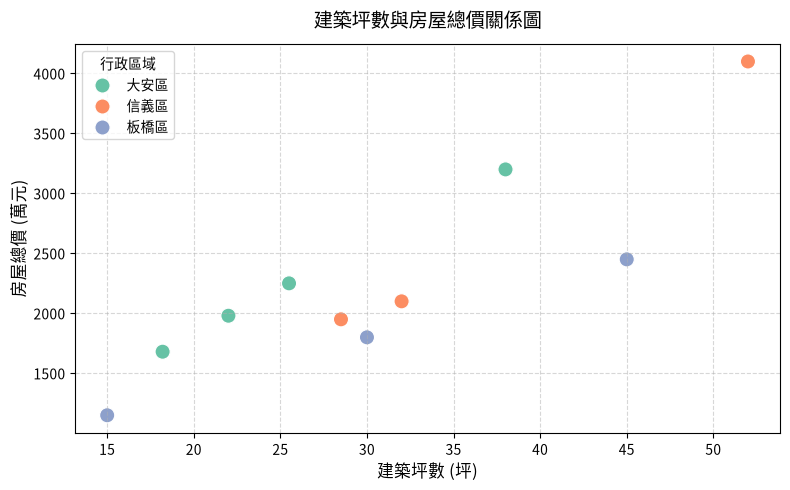

💡 觀念總結：特徵矩陣 X 是模型觀察的世界，標籤 y 則是模型要預測的解答！


In [10]:
# 儲存格 4：視覺化特徵與標籤的關係（散佈圖）
# Cell 4: Visualize the relationship between features and labels (Scatter plot)
# 3. 繪製特徵與標籤的關係圖：用圖形理解資料趨勢
# 3. Plot relationship between features and labels: understand data trends via graphics
# 新建圖形，設定寬 8 吋、高 5 吋
# Create a new figure, setting width to 8 inches and height to 5 inches

plt.figure(figsize=(8, 5))
# 繪製散佈圖：X=建築坪數，Y=房屋總價，並以行政區域上色區分
# Plot scatter plot: X=Building Area, Y=House Total Price, colored by administrative district

sns.scatterplot(data=df, x='建築坪數', y='房屋總價_萬元', hue='行政區域', s=120, palette='Set2')
# 設定圖表標題
# Set chart title

plt.title('建築坪數與房屋總價關係圖', fontsize=14, pad=12)
# 設定 X 軸標籤（含單位：坪）
# Set X-axis label (includes unit: Ping)

plt.xlabel('建築坪數 (坪)', fontsize=12)
# 設定 Y 軸標籤（含單位：萬元）
# Set Y-axis label (includes unit: 10k)

plt.ylabel('房屋總價 (萬元)', fontsize=12)
# 顯示虛線格線，提升數值判讀性
plt.grid(True, linestyle='--', alpha=0.5)
# 自動調整版面，避免標籤被裁切
# Automatically adjust layout to prevent label clipping

plt.tight_layout()
# 顯示圖表
# Display chart

plt.show()

# 觀念總結：特徵矩陣 X 是模型觀察的世界，標籤 y 則是模型要預測的解答！
# Concept Summary: Feature Matrix X is the world the model observes, Label Vector y is the answer the model predicts!

print("💡 觀念總結：特徵矩陣 X 是模型觀察的世界，標籤 y 則是模型要預測的解答！")